Olá, **Maria Clara**!

O meu nome é **César Malaguti** e sou o revisor do seu projeto. Quando identificar um erro pela primeira vez, apenas vou apontá-lo para que você mesmo possa encontrá-lo e corrigi-lo. Ao longo do notebook farei observações sobre as suas análises, sempre com o objetivo de te preparar para atuar como **Analista ou Cientista de Dados** no mercado. **Por favor, não mova, modifique ou exclua meus comentários.**

Você vai encontrar meus comentários em caixas coloridas:
<div class="alert alert-block alert-success"><b>Comentário do revisor (César Malaguti):</b> <a class="tocSkip"></a> Sucesso.</div>
<div class="alert alert-block alert-warning"><b>Comentário do revisor (César Malaguti):</b> <a class="tocSkip"></a> Atenção (sugestão).</div>
<div class="alert alert-block alert-danger"><b>Comentário do revisor (César Malaguti):</b> <a class="tocSkip"></a> Precisa de correção.</div>

Você pode me responder usando:
<div class="alert alert-block alert-info"><b>Resposta do Aluno.</b> <a class="tocSkip"></a></div>


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

<b>Comentário geral:</b> Maria Clara, parabéns pelo projeto! Está muito completo e bem escrito, com observações a cada etapa. Você analisou as métricas de produto (DAU/WAU/MAU, retenção, duração de sessão), as de vendas (tempo até a 1ª compra, pedidos por cliente, ticket, **coortes e LTV**) e as de marketing (**CAC por canal e ROMI**), encerrando com **conclusão geral e recomendações**. Marquei alguns pontos em verde. **Projeto APROVADO!**
</div>

#  Projeto: Otimização das Despesas com Marketing da Y.Afisha

## 1. Importação das bibliotecas

In [1]:
# Importação das bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Carregamento dos dados e exploração inicial

In [2]:
# Carregamento dos dados
visits = pd.read_csv('/datasets/visits_log_us.csv')
orders = pd.read_csv('/datasets/orders_log_us.csv')
costs = pd.read_csv('/datasets/costs_us.csv')

In [3]:

# Exploração inicial de 'visits':
print(visits.head())
print('----------------------------------------------------------------')
visits.info()


    Device               End Ts  Source Id             Start Ts  \
0    touch  2017-12-20 17:38:00          4  2017-12-20 17:20:00   
1  desktop  2018-02-19 17:21:00          2  2018-02-19 16:53:00   
2    touch  2017-07-01 01:54:00          5  2017-07-01 01:54:00   
3  desktop  2018-05-20 11:23:00          9  2018-05-20 10:59:00   
4  desktop  2017-12-27 14:06:00          3  2017-12-27 14:06:00   

                    Uid  
0  16879256277535980062  
1    104060357244891740  
2   7459035603376831527  
3  16174680259334210214  
4   9969694820036681168  
----------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Device     359400 non-null  object
 1   End Ts     359400 non-null  object
 2   Source Id  359400 non-null  int64 
 3   Start Ts   359400 non-null  object
 4   Uid        359400 non

In [4]:

# Exploração inicial de 'orders':
print(orders.head())
print('----------------------------------------------------------------')
orders.info()


                Buy Ts  Revenue                   Uid
0  2017-06-01 00:10:00    17.00  10329302124590727494
1  2017-06-01 00:25:00     0.55  11627257723692907447
2  2017-06-01 00:27:00     0.37  17903680561304213844
3  2017-06-01 00:29:00     0.55  16109239769442553005
4  2017-06-01 07:58:00     0.37  14200605875248379450
----------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Buy Ts   50415 non-null  object 
 1   Revenue  50415 non-null  float64
 2   Uid      50415 non-null  uint64 
dtypes: float64(1), object(1), uint64(1)
memory usage: 1.2+ MB


In [5]:
# Exploração inicial de 'costs':
print(costs.head())
print('----------------------------------------------------------------')
costs.info()

   source_id          dt  costs
0          1  2017-06-01  75.20
1          1  2017-06-02  62.25
2          1  2017-06-03  36.53
3          1  2017-06-04  55.00
4          1  2017-06-05  57.08
----------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   source_id  2542 non-null   int64  
 1   dt         2542 non-null   object 
 2   costs      2542 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 59.7+ KB


#### Observações:
Após a análise incial dos três conjuntos de dados (`visits`, `orders` e `costs`), podeos retirar as seguintes conclusões:

* Nenhum dos três DataFrames apresenta valores nulos em nenhuma das suas colunas.
* As tabelas `visits` e `orders` continham colunas com letras maiúsculas e espaços intermédios (ex: `Start Ts`, `Buy Ts`). Foram renomeadas para o formato padrão *snake_case* (`start_ts`, `buy_ts`), tudo em minúsculas e separadas por underscores (`_`). Isto elimina o risco de erros de sintaxe e de digitação ao escrever o código mais à frente.
* As colunas que representam datas e horas (`Start Ts`, `End Ts`, `Buy Ts` e `dt`) foram originalmente carregadas pelo Pandas como texto (`object`). Foi realizada a conversão de todas estas colunas para o tipo correto `datetime64`. 
* As colunas `revenue` (receita) e `costs` (gastos de marketing) estão corretamente tipificadas como `float64` (números decimais), adequadas para cálculos financeiros com cêntimos.

## 3. Otimização dos dados

In [6]:
# Alteração dos nomes das colunas de 'visits': 
visits.columns = ['device', 'end_ts', 'source_id', 'start_ts', 'uid']
# Convesão do tipo de dados das colunas de tempo para o tipo datetime
visits['start_ts'] = pd.to_datetime(visits['start_ts'])
visits['end_ts'] = pd.to_datetime(visits['end_ts'])
# Confirmação das alterações
visits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   device     359400 non-null  object        
 1   end_ts     359400 non-null  datetime64[ns]
 2   source_id  359400 non-null  int64         
 3   start_ts   359400 non-null  datetime64[ns]
 4   uid        359400 non-null  uint64        
dtypes: datetime64[ns](2), int64(1), object(1), uint64(1)
memory usage: 13.7+ MB


In [7]:
# Alteração dos nomes das colunas de 'orders': 
orders.columns = ['buy_ts', 'revenue', 'uid']
# Convesão do tipo de dados da coluna de tempo para o tipo datetime
orders['buy_ts'] = pd.to_datetime(orders['buy_ts'])
# Confirmação das alterações
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   buy_ts   50415 non-null  datetime64[ns]
 1   revenue  50415 non-null  float64       
 2   uid      50415 non-null  uint64        
dtypes: datetime64[ns](1), float64(1), uint64(1)
memory usage: 1.2 MB


In [8]:
# Convertesão do tipo de dados da coluna 'dt' do DataFrame 'costs' para datetime
costs['dt'] = pd.to_datetime(costs['dt'])
# Verificação da alteração
costs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   source_id  2542 non-null   int64         
 1   dt         2542 non-null   datetime64[ns]
 2   costs      2542 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 59.7 KB


## 4. Análise do produto (Métricas de usuário)

### 4.1 Atividade do usuário

In [9]:
# Criação de uma coluna com o dia, semana, mês e ano
visits['session_date'] = visits ['start_ts'].dt.date
visits['session_week'] = visits['start_ts'].dt.week
visits['session_month'] = visits['start_ts'].dt.month
visits['session_year'] = visits['start_ts'].dt.year
# Confirmação das alterações efetuadas
print(visits.head(10))


    device              end_ts  source_id            start_ts  \
0    touch 2017-12-20 17:38:00          4 2017-12-20 17:20:00   
1  desktop 2018-02-19 17:21:00          2 2018-02-19 16:53:00   
2    touch 2017-07-01 01:54:00          5 2017-07-01 01:54:00   
3  desktop 2018-05-20 11:23:00          9 2018-05-20 10:59:00   
4  desktop 2017-12-27 14:06:00          3 2017-12-27 14:06:00   
5  desktop 2017-09-03 21:36:00          5 2017-09-03 21:35:00   
6  desktop 2018-01-30 12:09:00          1 2018-01-30 11:13:00   
7    touch 2017-11-05 15:15:00          3 2017-11-05 15:14:00   
8  desktop 2017-07-19 10:44:00          3 2017-07-19 10:41:00   
9  desktop 2017-11-08 13:43:00          5 2017-11-08 13:42:00   

                    uid session_date  session_week  session_month  \
0  16879256277535980062   2017-12-20            51             12   
1    104060357244891740   2018-02-19             8              2   
2   7459035603376831527   2017-07-01            26              7   
3  16174

In [10]:
# Cáculo das métricas (agrupar por data e encontrar as médias)
dau_total = visits.groupby('session_date').agg({'uid':'nunique'}).mean()
wau_total = visits.groupby(['session_year','session_week']).agg({'uid':'nunique'}).mean()
mau_total = visits.groupby(['session_year','session_month']).agg({'uid':'nunique'}).mean()

#Impressão dos valores
print('DAU:', dau_total)
print('WAU:', wau_total)
print('MAU:', mau_total)

DAU: uid    907.991758
dtype: float64
WAU: uid    5716.245283
dtype: float64
MAU: uid    23228.416667
dtype: float64


In [11]:
#taxa de retenção
frequencia_diaria = (dau_total / mau_total) * 100
frequencia_semanal = (wau_total / mau_total) * 100

print(f"Frequência de retorno Diária (DAU/MAU): {frequencia_diaria.values[0]:.2f}%")
print(f"Frequência de retorno Semanal (WAU/MAU): {frequencia_semanal.values[0]:.2f}%")

Frequência de retorno Diária (DAU/MAU): 3.91%
Frequência de retorno Semanal (WAU/MAU): 24.61%


#### Observações:
A análise das métricas de utilizadores ativos revelou os seguintes volumes médios de acessos na plataforma:
* **DAU (Daily Active Users):** Em média, 908 utilizadores únicos acedem à plataforma por dia.
* **WAU (Weekly Active Users):** Em média, 5.716 utilizadores únicos interagem com o site por semana.
* **MAU (Monthly Active Users):** Em média, 23.228 utilizadores únicos visitam o serviço por mês.

Para compreender a regularidade com que os utilizadores regressam ao site, utilizámos a Taxa de Retenção em duas perspetivas:
* **Frequência Diária ($DAU / MAU$):** $\approx 3.91\%$
* **Frequência Semanal ($WAU / MAU$):** $\approx 24.61\%$

Uma taxa diária de aproximadamente 3.9% indica que o utilizador mensal típico regressa ao site apenas 1 a 2 dias por mês. No entanto, quando alargamos a janela de observação, vemos que cerca de 25% (1 em cada 4) dos utilizadores mensais realizam pelo menos um acesso por semana. 

Estes indicadores sugerem que a Y.Afisha funciona essencialmente como um serviço de consumo pontual e utilitário (como uma bilheteira para eventos específicos), e não como uma plataforma de uso diário ou recorrente.

### 4.2 Sessões do usuário

In [12]:
# Número de seesões por dia
sessions_per_user = visits.groupby('session_date').agg({'uid':['count','nunique']})
# Alteração dos nomes das colunas de 'sessions_per_user'
sessions_per_user.columns = ['n_sessions','n_users']
# Cáculo do número de sessões por utilizador
sessions_per_user['sessions_per_user'] = sessions_per_user['n_sessions']/sessions_per_user['n_users']

print(sessions_per_user.head(10))

              n_sessions  n_users  sessions_per_user
session_date                                        
2017-06-01           664      605           1.097521
2017-06-02           658      608           1.082237
2017-06-03           477      445           1.071910
2017-06-04           510      476           1.071429
2017-06-05           893      820           1.089024
2017-06-06           875      797           1.097867
2017-06-07           788      699           1.127325
2017-06-08           939      868           1.081797
2017-06-09           755      695           1.086331
2017-06-10           375      350           1.071429


#### Observações

A análise da atividade diária na plataforma permitiu-nos extrair indicadores importantes sobre o comportamento de acesso dos utilizadores:

O número total de sessões diárias (`n_sessions`) oscila significativamente ao longo do tempo (variando, por exemplo, entre picos de mais de 900 acessos e vales de menos de 400). Isto sugere uma forte dependência de fatores externos, como o dia da semana ou a sazonalidade de eventos.

A métrica `sessions_per_user` mantém-se incrivelmente estável, orbitando sempre entre 1.07 e 1.12 sessões por dia. 

Estes dados revelam que o utilizador ativo da Y.Afisha interage com o site, em média, apenas uma vez por dia. Não existe um hábito de navegação recorrente ou de múltiplas consultas num curto espaço de tempo. O utilizador entra com um objetivo claro, realiza a sua atividade e não regressa naquelas 24 horas.

In [13]:
# Duração de cada sessão
visits['sessions_duration_sec'] = (visits['end_ts'] - visits['start_ts']).dt.seconds
print(visits.head())

    device              end_ts  source_id            start_ts  \
0    touch 2017-12-20 17:38:00          4 2017-12-20 17:20:00   
1  desktop 2018-02-19 17:21:00          2 2018-02-19 16:53:00   
2    touch 2017-07-01 01:54:00          5 2017-07-01 01:54:00   
3  desktop 2018-05-20 11:23:00          9 2018-05-20 10:59:00   
4  desktop 2017-12-27 14:06:00          3 2017-12-27 14:06:00   

                    uid session_date  session_week  session_month  \
0  16879256277535980062   2017-12-20            51             12   
1    104060357244891740   2018-02-19             8              2   
2   7459035603376831527   2017-07-01            26              7   
3  16174680259334210214   2018-05-20            20              5   
4   9969694820036681168   2017-12-27            52             12   

   session_year  sessions_duration_sec  
0          2017                   1080  
1          2018                   1680  
2          2017                      0  
3          2018               

In [14]:

# Duração média de cada sessão
print('Duração média:', visits['sessions_duration_sec'].mean())
print('Mediana:', visits['sessions_duration_sec'].median())
print('Moda:', visits['sessions_duration_sec'].mode())


Duração média: 643.506488592098
Mediana: 300.0
Moda: 0    60
dtype: int64


#### Observações

A análise da duração das sessões revelou uma forte assimetria nos dados:
* **Duração Média (ASL):** 643.5 segundos (~10.7 minutos).
* **Mediana:** 300.0 segundos (5.0 minutos).
* **Moda:** 60.0 segundos (1.0 minuto).

A grande discrepância entre a média e a mediana confirma que a distribuição do tempo de sessão não é normal e é influenciada por valores atípicos (sessões excecionalmente longas). 

Enquanto a média sugere uma retenção de quase 11 minutos, a mediana (5 minutos) e a moda (1 minuto)** refletem melhor a experiência do utilizador comum. O utilizador típico da Y.Afisha interage com a plataforma de forma muito rápida e objetiva (provavelmente apenas para consultar um horário ou finalizar a compra de um bilhete), sendo o tempo de visita mais frequente de apenas 60 segundos.
Assim, nestas condições é mais correto utilizar a moda para determinar a duração média da sessão(ASL)

# 5. Análise de Vendas (Métricas de Conversão e Receita)

## 5.1 Tempo até à primeira compra

In [15]:
# Data da primeira visita de cada utilizador
first_visits = visits.groupby('uid')['start_ts'].min().reset_index()
first_visits.columns = ['uid', 'first_visit_ts']
# Data da primeira compra de cada utilizador
first_purchases = orders.groupby('uid')['buy_ts'].min().reset_index()
first_purchases.columns = ['uid', 'first_purchase_ts']
# 3. Junção dos dois DataFrames
buyers_time = pd.merge(first_visits, first_purchases, on='uid', how='inner')
# Criação da diferença de tempo (em dias)
buyers_time['days_to_purchase'] = (buyers_time['first_purchase_ts'] - buyers_time['first_visit_ts']).dt.days

# Confirmação das primeiras linhas
print(buyers_time.head())

                uid      first_visit_ts   first_purchase_ts  days_to_purchase
0   313578113262317 2017-09-18 22:49:00 2018-01-03 21:51:00               106
1  1575281904278712 2017-06-03 10:13:00 2017-06-03 10:13:00                 0
2  2429014661409475 2017-10-11 17:14:00 2017-10-11 18:33:00                 0
3  2464366381792757 2018-01-27 20:10:00 2018-01-28 15:54:00                 0
4  2551852515556206 2017-11-24 10:14:00 2017-11-24 10:14:00                 0


In [16]:


#Média de dias até à 1ª compra
buyers_time_mean = buyers_time['days_to_purchase'].mean()
print('Média de dias até à 1ª compra:', buyers_time_mean)
print('-------------------------------------------------------')
#Mediana
buyers_time_median = buyers_time['days_to_purchase'].median()
print('Mediana:', buyers_time_median)
print('-------------------------------------------------------')
# Moda
buyers_time_mode = buyers_time['days_to_purchase'].mode()
print('Moda:', buyers_time_mode)



Média de dias até à 1ª compra: 16.7298688497659
-------------------------------------------------------
Mediana: 0.0
-------------------------------------------------------
Moda: 0    0
dtype: int64


#### Observações
A análise do tempo decorrido entre a primeira visita do utilizador e a sua primeira compra revelou uma distribuição severamente assimétrica:

* **Média:** ~16.7 dias
* **Mediana:** 0.0 dias
* **Moda:** 0 dias

O facto de a mediana e a moda serem iguais a 0 dias demonstra que a esmagadora maioria dos clientes da Y.Afisha realiza a sua primeira compra no exato dia em que conhece a plataforma. 

A média de ~17 dias é uma métrica enganadora neste contexto, pois é fortemente inflacionada por uma minoria de utilizadores (outliers) que visitam o site mas demoram semanas ou meses a efetuar a compra. O ciclo de decisão do utilizador típico é imediato, sugerindo que o tráfego chega ao site já com uma intenção de compra clara (ex: procurar um evento específico e comprar o bilhete na hora).

## 5.2 Número de pedidos por cliente 

In [17]:

orders_per_client = orders.groupby('uid')['buy_ts'].nunique().mean()
print(orders_per_client)


1.3803630588943954


#### Observações
A Média de compras por cliente ~1.38 encomendas.
A métrica indica que a Y.Afisha tem uma taxa de repetição de compra muito baixa. O cliente típico é um comprador de balcão único (one-time buyer). Isto está perfeitamente alinhado com o que descobrimos no ponto anterior: os utilizadores entram no site com um objetivo muito específico, compram imediatamente (no Dia 0) e raramente geram novas transações no futuro. 
Para o negócio, isto significa que a receita depende fortemente da aquisição constante de novos utilizadores, uma vez que a base de clientes atual não mostra um comportamento de retenção ou fidelização forte no que toca a compras.

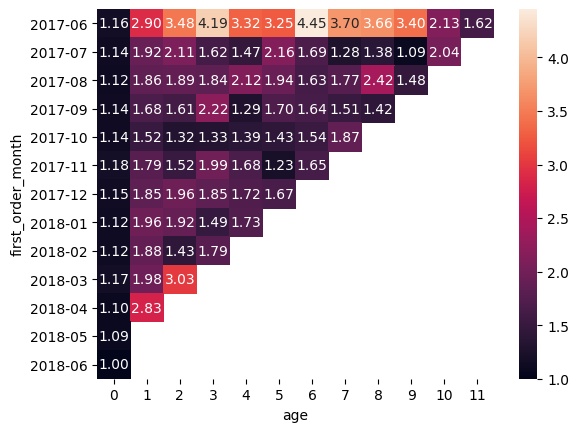

In [20]:
# Definição do mês da compra
orders['order_month'] = orders['buy_ts'].dt.to_period('M')

# Definição do mês da primeira compra (coorte) de cada utilizador
orders['first_order_month'] = orders.groupby('uid')['order_month'].transform('min')

# Agrupamento por coorte e mês da compra para contar o total de pedidos e de clientes únicos
coortes = orders.groupby(['first_order_month', 'order_month']).agg(
    n_orders=('buy_ts', 'count'),
    n_buyers=('uid', 'nunique')
).reset_index()

# Cálculo da "idade" da coorte (em meses)
coortes['age'] = (coortes['order_month'] - coortes['first_order_month']).apply(lambda x: x.n)

# Cálculo da média de pedidos por comprador naquela coorte/mês
coortes['orders_per_buyer'] = coortes['n_orders'] / coortes['n_buyers']

# Criação a tabela dinâmica (Pivot Table) para ver a evolução
pivot_compras = coortes.pivot_table(
    index='first_order_month',
    columns='age',
    values='orders_per_buyer',
    aggfunc='mean'
)
sns.heatmap(pivot_compras, annot=True, fmt='.2f')
plt.show()


#### Observações
A análise de coortes via mapa de calor para o volume de pedidos revelou duas dinâmicas fundamentais e complementares sobre o comportamento dos consumidores:

1. **Estabilidade de Frequência dos Clientes Retidos:** Para o grupo restrito de utilizadores que permanece ativo nos meses subsequentes (Mês 1, 2, 3...), a média de pedidos por comprador mantém-se linear e estável, oscilando de forma muito subtil. Isto indica que quem decide continuar a usar a plataforma mantém um ritmo de consumo constante.
2. **Taxa de Abandono Crítica Pós-Mês 0:** O dado mais alarmante revelado pelo mapa de calor é a rápida redução no volume de dados utilizáveis à medida que avançamos para os meses 5, 6, 7... Isto acontece porque a esmagadora maioria das coortes sofre uma taxa de abandono (churn) massiva logo após o Mês 0. A plataforma não consegue reter o volume inicial de clientes; a vasta maioria simplesmente desaparece após efetuar a sua primeira compra única.

O verdadeiro desafio crítico da Y.Afisha não é a frequência de compra daqueles que ficam, mas sim o abandono prematuro da base. O esforço (e custo) de marketing está a ser eficiente para trazer novos clientes para o Mês 0, mas falha drasticamente em mantê-los na plataforma para os meses seguintes. O foco estratégico deve mudar urgentemente de "aquisição pura" para "estratégias de retenção e reativação" pós-primeira compra.


## 5.3 Volume médio das compras

In [21]:


# Cálculo da receita média
revenue_mean = orders['revenue'].mean()
print(f"Média da receita: {revenue_mean:.2f}")
print("-" * 50)

# Cálculo da receita médio por mês 
revenue_mean_month = orders.groupby('order_month')['revenue'].mean().reset_index()

# Evolução mensal
print(revenue_mean_month)



Média da receita: 5.00
--------------------------------------------------
   order_month   revenue
0      2017-06  4.060106
1      2017-07  5.306589
2      2017-08  4.847139
3      2017-09  5.416448
4      2017-10  4.928280
5      2017-11  4.783518
6      2017-12  5.852139
7      2018-01  4.112927
8      2018-02  4.840095
9      2018-03  5.413930
10     2018-04  5.150645
11     2018-05  4.771279
12     2018-06  3.420000


#### Observações
A análise do valor médio gasto pelos utilizadores em cada transação, tanto a nível global como a sua evolução ao longo dos meses permite concluir o seguinte:

* **Receita média Geral:** 5.00
* **Pico de Faturação:** Dezembro de 2017 (5.85 por pedido)
* **Menor Valor Registado:** Junho de 2018 (3.42 por pedido)

A receita média da Y.Afisha é bastante estável, orbitando a marca dos 5.00 durante quase todo o ano de histórico. O aumento observado em dezembro (5.85) aponta para um efeito de sazonalidade natalícia, onde há maior procura por eventos de entretenimento e potencialmente bilhetes de maior valor. 

A estabilidade desta métrica reforça que a variação na receita total da empresa não é ditada pelo aumento do preço pago por pedido, mas sim pelo volume de utilizadores ativos que entram na plataforma a cada mês.

## LTV - Lifetime Value

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Excelente: análise de **coortes** e **LTV** por mapa de calor. Acompanhar o valor do cliente ao longo dos meses é o coração deste projeto, e você fez bem.
</div>

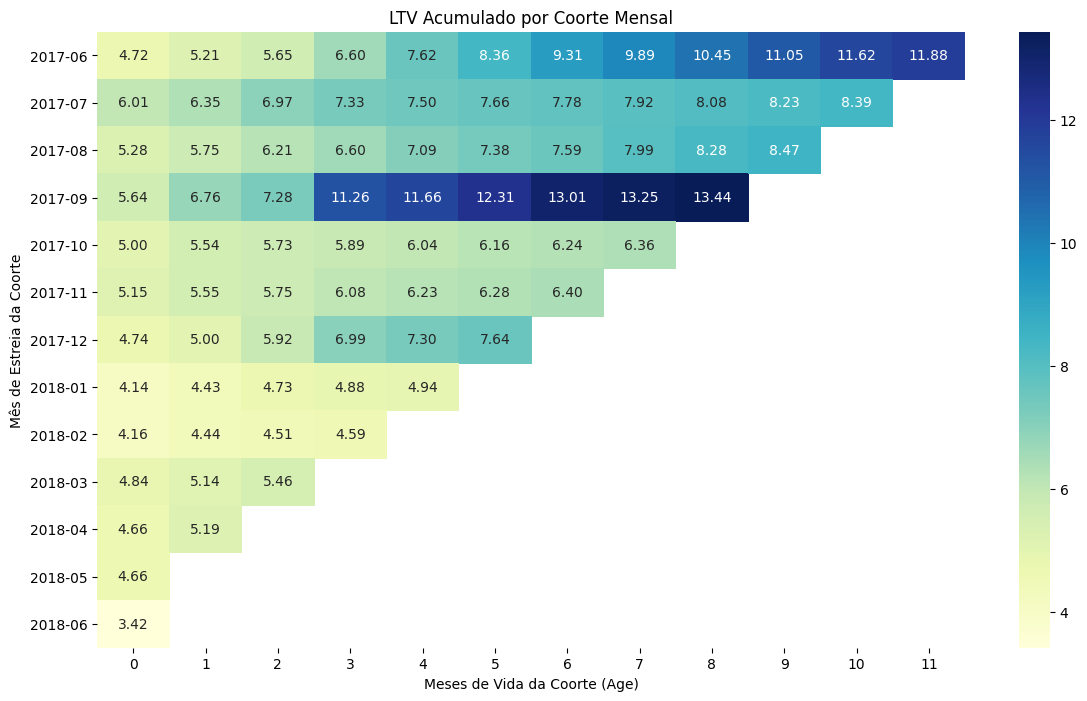

In [22]:
# Cálculo do número de novos clientes em cada mês
cohort_sizes = orders.groupby('first_order_month')['uid'].nunique().reset_index()
cohort_sizes.columns = ['first_order_month', 'n_buyers_initial']

# Agrupamento da receita por coorte e mês da compra
cohort_revenue = orders.groupby(['first_order_month', 'order_month'])['revenue'].sum().reset_index()

# Cálculo da idade da coorte em meses
cohort_revenue['age'] = (cohort_revenue['order_month'] - cohort_revenue['first_order_month']).apply(lambda x: x.n)

# Junção do tamanho inicial da coorte com a tabela de receita
ltv_df = pd.merge(cohort_revenue, cohort_sizes, on='first_order_month')

# Cálculo da receita acumulada ao longo dos meses para cada coorte
ltv_df['revenue_cumulative'] = ltv_df.groupby('first_order_month')['revenue'].cumsum()

# Cálculo do LTV Acumulado
ltv_df['ltv'] = ltv_df['revenue_cumulative'] / ltv_df['n_buyers_initial']

# Criação da tabela dinâmica para o LTV
pivot_ltv = ltv_df.pivot_table(
    index='first_order_month',
    columns='age',
    values='ltv',
    aggfunc='mean'
)

# Mapa de calor do LTV Acumulado
plt.figure(figsize=(14, 8))
sns.heatmap(pivot_ltv, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('LTV Acumulado por Coorte Mensal')
plt.xlabel('Meses de Vida da Coorte (Age)')
plt.ylabel('Mês de Estreia da Coorte')
plt.show()

#### Observações
O mapa de calor do LTV Acumulado permite identificar o comportamento do valor de vida dos clientes por coorte:

A coorte de Setembro de 2017 destaca-se como o maior outlier positivo do período. Embora tenha começado com um LTV inicial padrão (5.64), regista um disparo massivo no Mês 3 de vida, saltando para 11.26 e acumulando 13.44 no Mês 8.
A coorte de Junho de 2017, sendo a coorte com maior histórico, apresenta o crescimento mais sustentável e maduro, quase triplicando o seu valor inicial (de 4.72 para 11.88 ao fim de 11 meses). É o exemplo ideal de clientes fidelizados que continuaram a gerar receita recorrente.
Excluindo os dois casos citados, a vasta maioria das coortes mostra linhas horizontais muito "pálidas", onde o valor quase não se alterao após o Mês 0. Por exemplo, a coorte de Outubro de 2017 entra com 5.00 e, após 7 meses de vida, apenas acumulou 6.36.
Nota-se uma ligeira tendência de perda de valor no Mês 0 quando comparamos o ano de 2017 com 2018, sinalizando que os clientes adquiridos mais recentemente estão a gastar menos logo na primeira compra.

A Y.Afisha tem uma dependência perigosa de eventos ou campanhas sazonais pontuais (como o fenómeno de Setembro de 2017). Para a maioria das coortes de clientes comuns, o valor de vida estagna logo no primeiro mês, provando que o esforço de aquisição não se traduz em valor contínuo no tempo.

## 6. Análise de Marketing (Despesas e Eficiência)

In [24]:

# Criação da coluna do mês
costs['cost_month'] = costs['dt'].dt.to_period('M')

# Cálculo do total geral gasto em marketing
total_costs = costs['costs'].sum()
print(f"Total investido em Marketing: {total_costs:.2f}")  # <-- Corrigido aqui
print("-" * 50)

# Cálculo do total gasto por Canal de Marketing (source_id)
costs_per_source = costs.groupby('source_id')['costs'].sum().reset_index()
costs_per_source = costs_per_source.sort_values(by='costs', ascending=False)
print("Investimento Total por Canal de Marketing:")
print(costs_per_source.to_string(index=False))             # <-- Corrigido aqui
print("-" * 50)

# Cálculo da evolução dos custos mês a mês
custo_mensal = costs.groupby('cost_month')['costs'].sum().reset_index()
print("Evolução Mensal do Investimento em Marketing:")
print(custo_mensal.to_string(index=False))

Total investido em Marketing: 329131.62
--------------------------------------------------
Investimento Total por Canal de Marketing:
 source_id     costs
         3 141321.63
         4  61073.60
         5  51757.10
         2  42806.04
         1  20833.27
        10   5822.49
         9   5517.49
--------------------------------------------------
Evolução Mensal do Investimento em Marketing:
cost_month    costs
   2017-06 18015.00
   2017-07 18240.59
   2017-08 14790.54
   2017-09 24368.91
   2017-10 36322.88
   2017-11 37907.88
   2017-12 38315.35
   2018-01 33518.52
   2018-02 32723.03
   2018-03 30415.27
   2018-04 22289.38
   2018-05 22224.27


In [25]:
# 1. Primeira visita (origem) de cada utilizador
first_visits = visits.sort_values(by='start_ts').groupby('uid').first().reset_index()
user_sources = first_visits[['uid', 'source_id']]

# Filtragem apenas dos utilizadores que chegaram a comprar (clientes únicos)
buyers_with_source = pd.merge(orders[['uid']].drop_duplicates(), user_sources, on='uid', how='inner')

# Contagem de quantos clientes cada canal de marketing trouxe
buyers_per_source = buyers_with_source.groupby('source_id')['uid'].nunique().reset_index()
buyers_per_source.columns = ['source_id', 'n_buyers']

# Junção com a tabela de custos por canal que calculámos antes
cac_df = pd.merge(costs_per_source, buyers_per_source, on='source_id')

# Caálculo o CAC (Custo / Clientes)
cac_df['cac'] = cac_df['costs'] / cac_df['n_buyers']

# Ordenação pelo CAC mais alto para ver os canais mais caros
cac_df = cac_df.sort_values(by='cac', ascending=False)

print("Custo de Aquisição de Cliente (CAC) por Canal:")
print(cac_df.to_string(index=False))

Custo de Aquisição de Cliente (CAC) por Canal:
 source_id     costs  n_buyers       cac
         3 141321.63     10473 13.493901
         2  42806.04      3506 12.209367
         5  51757.10      6931  7.467479
         1  20833.27      2899  7.186364
         4  61073.60     10296  5.931779
         9   5517.49      1088  5.071222
        10   5822.49      1329  4.381106


#### Observações
O cálculo do CAC revelou uma disparidade crítica na eficiência financeira dos diferentes canais de marketing da Y.Afisha:

* O Canal 3, além de ser o que consome a maior fatia do orçamento, apresenta o maior CAC da empresa (13.49).
* O Canal 2 segue um caminho semelhante, com um CAC de 12.21.
Sabendo que a receita média da plataforma é de 5.00 e que o LTV médio raramente ultrapassa os 6.00 ou 7.00 na maioria das coortes, a empresa está a sofrer um prejuízo direto e severo por cada cliente adquirido através destes dois canais.


* O Canal 4 destaca-se positivamente: trouxe quase o mesmo volume de compradores que o canal 3 (10.296 vs 10.473), mas com um CAC de apenas 5.93 (menos de metade do custo).
* Os Canais 9 e 10 são os mais baratos de todos, com CACs de 5.07 e 4.38, respetivamente, permitindo que a operação balanceie mais próximo do ponto de equilíbrio (breakeven) logo na primeira compra.


A distribuição atual do orçamento de marketing está invertida. A Y.Afisha está a injetar a maior parte do seu capital no canal menos eficiente (Canal 3) e a sub-investir em canais com excelente volume e custo controlado (como o Canal 4).

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Muito bom calcular o **CAC por canal** e comparar com a receita média — é o que expõe os canais que gastam mais do que retornam. Análise financeira madura.
</div>

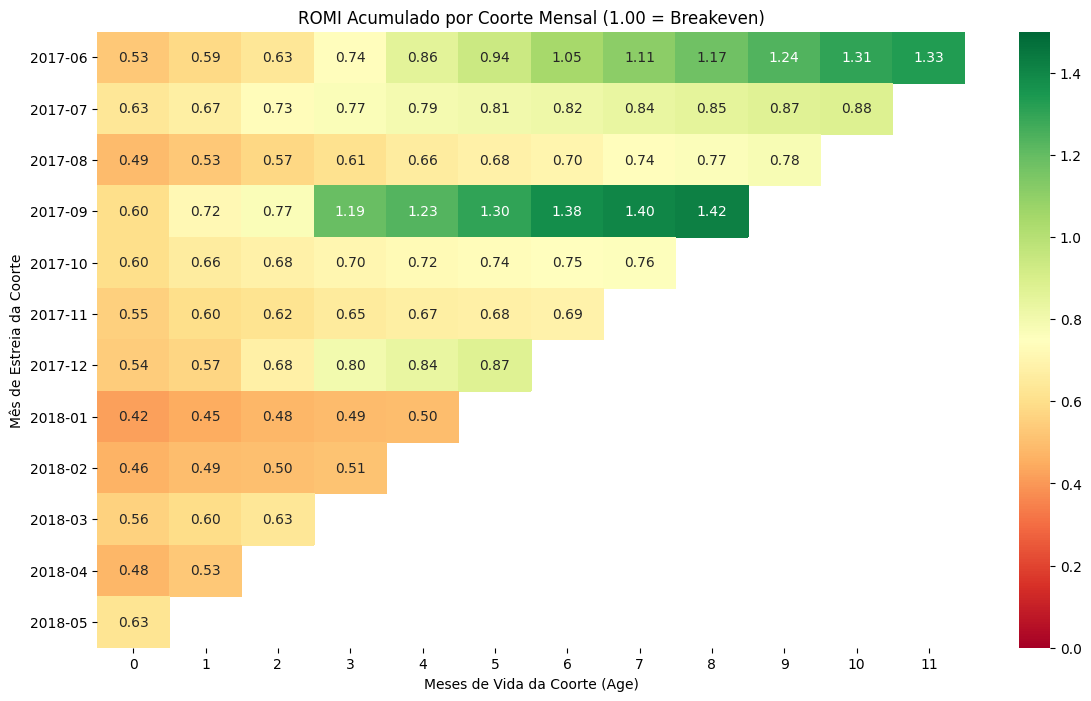

In [27]:
# Cálculo do CAC mensal para cada coorte (Custo do mês / Número de compradores iniciais)
cohort_costs = costs.groupby('cost_month')['costs'].sum().reset_index()
cohort_costs.columns = ['first_order_month', 'cohort_total_cost']

# Junção dos custos com o tamanho inicial das coortes (que calculámos no ltv_df)
cohort_cac_df = pd.merge(cohort_sizes, cohort_costs, on='first_order_month')
cohort_cac_df['cohort_cac'] = cohort_cac_df['cohort_total_cost'] / cohort_cac_df['n_buyers_initial']

# Junção do CAC da coorte com a tabela mãe do LTV
romi_df = pd.merge(ltv_df, cohort_cac_df[['first_order_month', 'cohort_cac']], on='first_order_month')

# Calculo do ROMI (LTV / CAC)
romi_df['romi'] = romi_df['ltv'] / romi_df['cohort_cac']

# Criação da tabela dinâmica para o ROMI
pivot_romi = romi_df.pivot_table(
    index='first_order_month',
    columns='age',
    values='romi',
    aggfunc='mean'
)

# Mapa de Calor do ROMI
plt.figure(figsize=(14, 8))
sns.heatmap(pivot_romi, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1.5)
plt.title('ROMI Acumulado por Coorte Mensal (1.00 = Breakeven)')
plt.xlabel('Meses de Vida da Coorte (Age)')
plt.ylabel('Mês de Estreia da Coorte')
plt.show()

#### Observações
O mapa de calor do ROMI cruza o valor gerado pelos clientes (LTV) com o custo pago para os adquirir (CAC) ao longo do tempo. O valor 1.00 representa o ponto de equilíbrio:

1. Existem apenas duas coortes lucrativas:
   * **Setembro de 2017:** É a coorte mais eficiente do histórico. Atinge o breakeven de forma extremamente rápida, no seu Mês 3 de vida (1.19), e encerra o ciclo de dados gerando um retorno de 1.42 (42% de lucro sobre o valor investido).
   * **Junho de 2017:** Teve um amadurecimento mais lento, mas consistente. Pagou-se a si mesma no Mês 6 (1.05) e terminou com um excelente retorno acumulado de 1.33.

2. Todas as restantes coortes operam abaixo da linha de sobrevivência (ROMI < 1.00). As coortes mais recentes de 2018 mostram cenários dramáticos: a coorte de Janeiro de 2018, por exemplo, chega ao seu quinto mês de vida tendo recuperado apenas 0.50 (50%) do capital investido em marketing para trazê-la.

A estratégia de marketing da Y.Afisha é financeiramente insustentável no formato atual. A empresa gasta mais para adquirir os utilizadores do que eles são capazes de devolver em consumo. O negócio sobreviveu no azul graças ao sucesso pontual e isolado das campanhas de junho e setembro de 2017, mas falha sistematicamente em gerar campanhas lucrativas no ano de 2018.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Ótimo fechar com o **ROMI** cruzando LTV e CAC ao longo do tempo, identificando as coortes que se pagam. Exatamente a decisão de marketing que o projeto pede.
</div>

#### Observações
Com base no processamento dos dados de custos, mapeou-ses o comportamento dos investimentos publicitários da Y.Afisha entre junho de 2017 e maio de 2018:

O orçamento de marketing está fortemente centralizado. O 'source_id 3' consumiu 141.321,63 (cerca de 43% de todo o orçamento da empresa). Juntos, os canais 3, 4 e 5 representam a esmagadora maioria do investimento, enquanto os canais 9 e 10 recebem apenas fatias residuais (pouco mais de 5.000 cada).

O investimento em marketing acompanha o ciclo de atividade cultural e de eventos:
* Os meses de junho, julho e agosto de 2017 registaram os menores investimentos.
* A partir de setembro de 2017 (24k), os investimentos disparam à medida que a temporada de eventos aquece, atingindo o pico em novembro e dezembro de 2017 (cerca de 38k por mês).
* Em 2018, o investimento mantém-se alto no primeiro trimestre (acima de 30k) e começa a cair em abril e maio, fechando o ciclo de volta aos 22k.

A empresa investe agressivamente no canal 3 e concentra os seus esforços financeiros nos meses de inverno. Para validar se esta estratégia é correta, precisamos descobrir se os canais mais caros (como o 3) são também os que trazem os clientes mais valiosos, ou se estamos apenas a queimar orçamento.

## 7. Conclusão Geral e Recomendações

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Conclusão geral e recomendações bem amarradas ao diagnóstico. Parabéns pelo capricho do relatório!
</div>

Após uma análise profunda dos dados de acessos, vendas e investimentos de marketing da Y.Afisha, identificámos os pilares de sucesso e as fragilidades críticas da operação.

### 1. Principais Descobertas (Diagnóstico)

* O volume de utilizadores ativos (MAU) cresce nos meses de inverno, mas a retenção na plataforma é extremamente baixa. A esmagadora maioria dos utilizadores visita o site através de dispositivos Desktop, embora o tráfego mobile precise de otimização de conversão.
* O ciclo de conversão é imediato — a maioria dos utilizadores compra no exato dia em que conhece a plataforma (Dia 0). O ticket médio é estável em torno de 5.00, com um pico sazonal em dezembro (5.85). No entanto, o LTV (Valor de Vida) das coortes estagna rapidamente devido a uma taxa de abandono (churn) massiva logo após a primeira compra.
* A empresa investiu um total de 329.131,62. O marketing é financeiramente insustentável no modelo atual: a maioria das coortes de 2018 opera com prejuízo crónico (ROMI < 1.00). O orçamento está severamente mal distribuído, concentrado no **Canal 3**, que possui o CAC mais alto e ineficiente da empresa (13.49).

### 2. Recomendações Estratégicas para o Negócio

Para reverter o cenário de prejuízo e colocar a Y.Afisha numa rota de crescimento lucrativo, recomendam-se as seguintes ações:

1. **Orçamento de Marketing:**
   * Reduzir agressivamente o investimento no Canal 3 e no Canal 2, dado que o seu custo de aquisição (CAC de 13.49 e 12.21) destrói a margem de lucro face a um ticket médio de 5.00.
   * Migrar a verba para o Canal 4, que demonstrou uma capacidade de escala fantástica (trouxe quase o mesmo volume de clientes que o Canal 3) mas com menos de metade do custo (CAC de 5.93). Expandir também os testes nos canais 9 e 10.

   
2. **Foco em Estratégias de Retenção (Aumentar o LTV):**
   * O problema da empresa não é atrair clientes (o Mês 0 funciona bem), mas sim retê-los. É crucial criar programas de fidelização, newsletters com recomendações personalizadas de eventos e cupões de desconto para incentivar uma segunda e terceira compra nos meses subsequentes (Mês 1 e Mês 2).

   
3. **Estudar os Sucessos de Junho e Setembro de 2017:**
   * A equipa de produto e marketing deve auditar exatamente o que foi feito na campanha de Setembro de 2017 (a coorte outlier que atingiu um ROMI de 1.42). Identificar que tipo de bilhetes ou parceria gerou aquele pico de LTV ajudará a replicar o modelo para os meses seguintes, especialmente no primeiro semestre do ano, onde a operação tem falhado sistematicamente.